# Results: original and estimated dates

In [1]:
import sys
import tempfile

import duckdb
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Dates of `individual_enriched` (ingested by `ingest_dates.py` from notebooks 01, 02 and 04):
- **Original**: the date comes from Wikidata (`source = 'wikidata'`), coarse dates included.
- **Estimated**: the date was imputed (`source = 'estimated'`).
- **Original work period**: first and last dated works (inception, else publication) in different years.
- **Estimated work period**: first and last work years imputed from the birth and death dates.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
dates = con.sql('''
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.birth_date.year AS birth_year,
           individual_enriched.death_date.year AS death_year,
           individual_enriched.birth_date.source AS birth_source,
           individual_enriched.death_date.source AS death_source,
           individual_enriched.birth_date.coarse_label IS NOT NULL OR individual_enriched.death_date.coarse_label IS NOT NULL AS coarse,
           len(individual.floruit_date) > 0 AS floruit,
           individual_enriched.first_work_date.source AS work_source,
           individual_enriched.first_work_date.year AS first_work_year,
           individual_enriched.last_work_date.year AS last_work_year
    FROM individual_enriched
    JOIN individual ON individual.entity.qid = individual_enriched.entity.qid
''').pl()
assert dates['qid'].is_unique().all()
print(f'{dates.height:,} individuals')
dates.sample(5, seed=42)

13,002,897 individuals


qid,birth_year,death_year,birth_source,death_source,coarse,floruit,work_source,first_work_year,last_work_year
str,i64,i64,str,str,bool,bool,str,i64,i64
"""Q136408214""",1893,1962,"""wikidata""","""wikidata""",false,false,"""estimated""",1933,1949
"""Q64064518""",1979,null,"""wikidata""",null,false,false,"""dated works""",2008,2019
"""Q108101212""",1992,null,"""wikidata""",null,false,false,null,null,null
"""Q27120556""",1952,null,"""wikidata""",null,false,false,null,null,null
"""Q88162217""",null,null,null,null,false,false,null,null,null


## Counts

In [3]:
period = pl.col('first_work_year') < pl.col('last_work_year')
counts = {
    'Original birth date': pl.col('birth_source') == 'wikidata',
    'Estimated birth date': pl.col('birth_source') == 'estimated',
    'Original death date': pl.col('death_source') == 'wikidata',
    'Estimated death date': pl.col('death_source') == 'estimated',
    'Original work period': (pl.col('work_source') == 'dated works') & period,
    'Estimated work period': pl.col('work_source') == 'estimated',
}
results = pl.DataFrame([
    {'dates': name, 'individuals': dates.filter(rule).height, 'share of the database (%)': 100 * dates.filter(rule).height / dates.height}
    for name, rule in counts.items()
])
single_year = dates.filter((pl.col('work_source') == 'dated works') & ~period).height
print(f'{single_year:,} individuals with dated works all in one year: neither an original nor an estimated work period')

250,976 individuals with dated works all in one year: neither an original nor an estimated work period


### Table: original and estimated dates

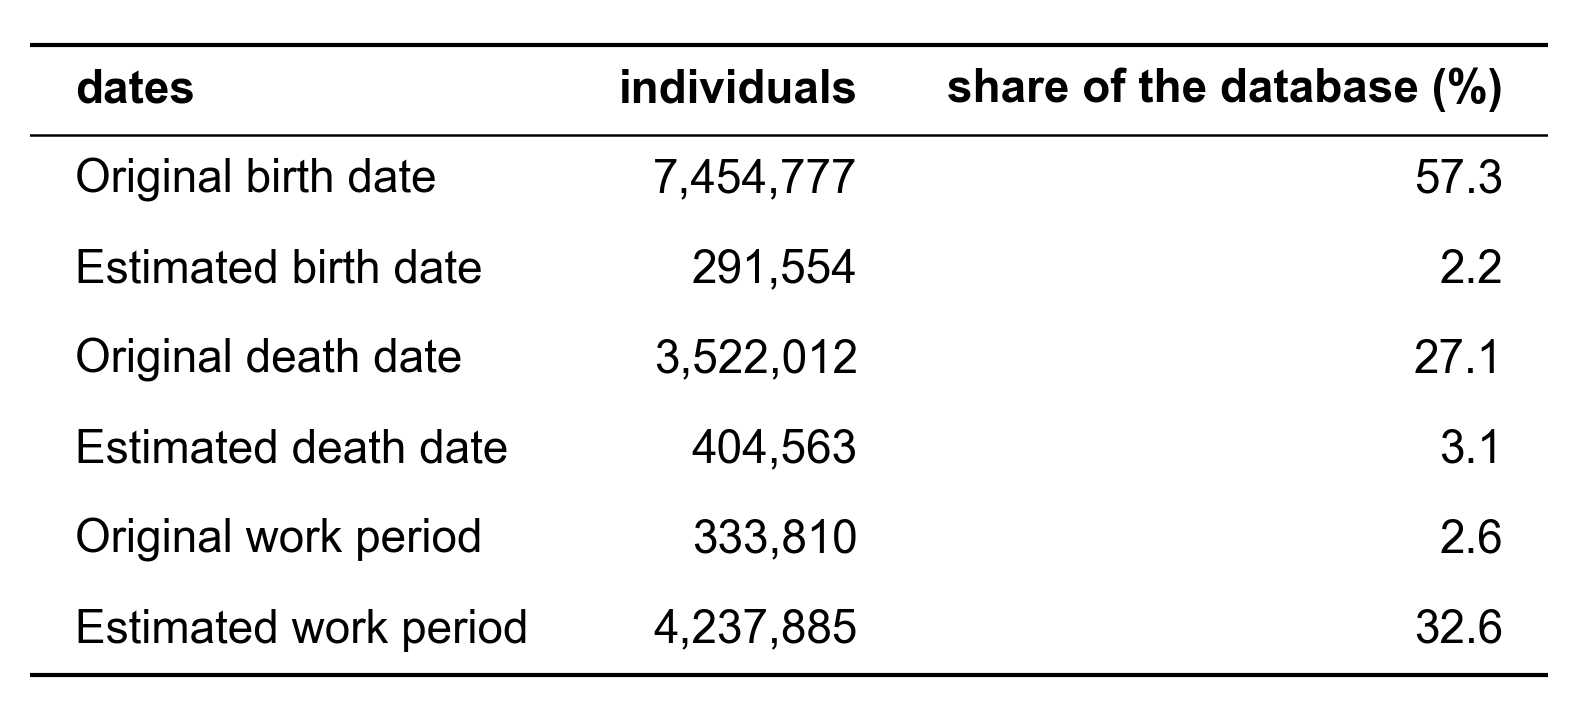

In [4]:
show_table(results, decimals=1)

## Without individuals born after 1920
Individuals with an original or estimated birth year after 1920 are removed; individuals without a birth year are kept. Shares are relative to the remaining individuals.

In [5]:
before_1920 = dates.filter(pl.col('birth_year').is_null() | (pl.col('birth_year') <= 1920))
results_before_1920 = pl.DataFrame([
    {'dates': name, 'individuals': before_1920.filter(rule).height, 'share of the database (%)': 100 * before_1920.filter(rule).height / before_1920.height}
    for name, rule in counts.items()
])
print(f'{dates.height - before_1920.height:,} individuals born after 1920 removed, {before_1920.height:,} remaining')

4,552,759 individuals born after 1920 removed, 8,450,138 remaining


### Table: original and estimated dates, individuals born up to 1920

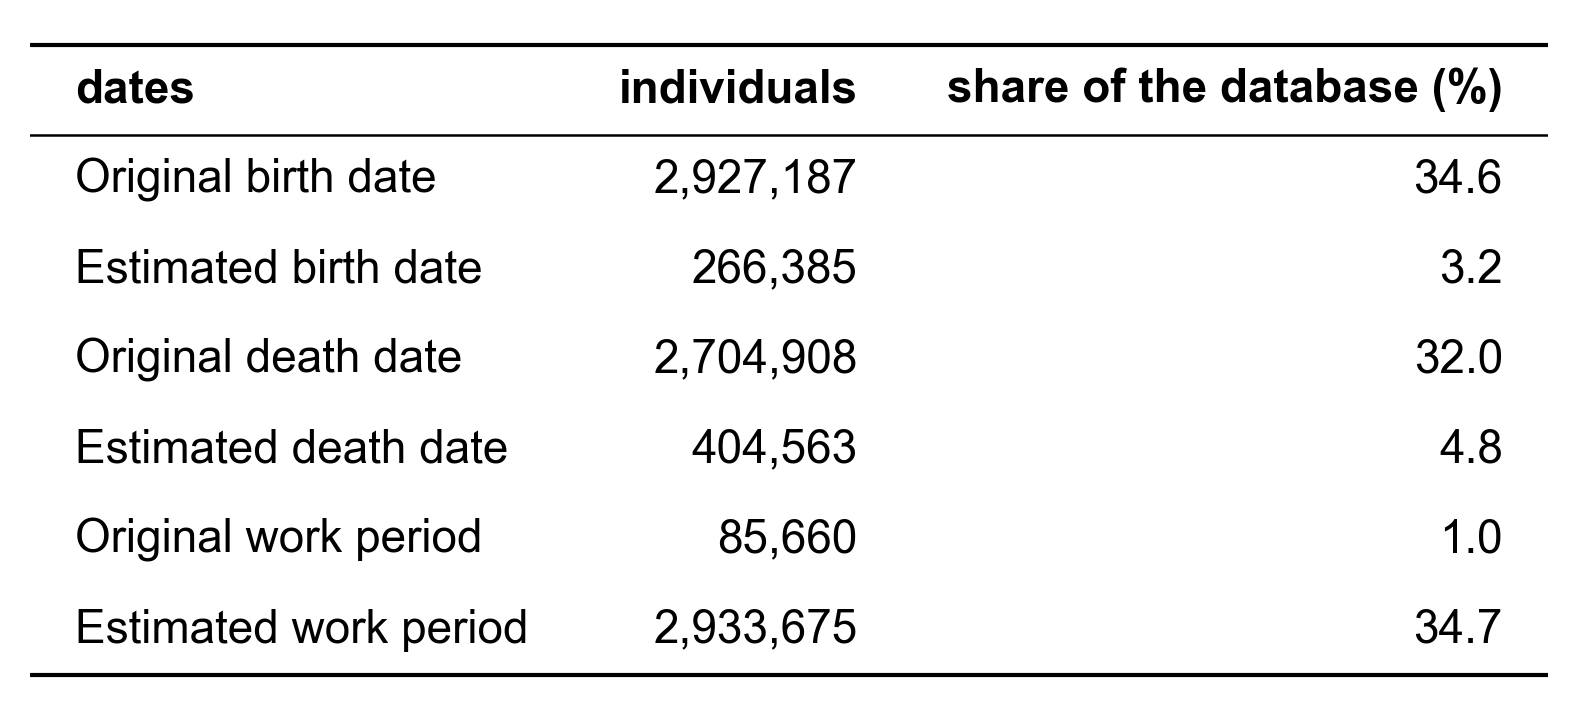

In [6]:
show_table(results_before_1920, decimals=1)

## Summary of what the method added
Cut-offs: a death is estimated only for individuals born up to 1920 (they may still be alive otherwise); a work period is estimated only for individuals born up to 1950 (from Wikidata, else the birth estimated from the age at death), with no dated work.

In [7]:
def first_match(rules):
    """The name of the first rule an individual matches."""
    expression = pl.lit(None, pl.String)
    for name, rule in reversed(rules.items()):
        expression = pl.when(rule).then(pl.lit(name)).otherwise(expression)
    return expression


wikidata_birth = (pl.col('birth_source') == 'wikidata') & pl.col('birth_year').is_not_null()
wikidata_death = (pl.col('death_source') == 'wikidata') & pl.col('death_year').is_not_null()
single_year = (pl.col('work_source') == 'dated works') & ~period
GROUPS = {
    'Birth and death, born up to 1950': wikidata_birth & wikidata_death & (pl.col('birth_year') <= 1950),
    'Birth and death, born after 1950': wikidata_birth & wikidata_death,
    'Birth only, born up to 1920': wikidata_birth & (pl.col('birth_year') <= 1920),
    'Birth only, born 1921–1950': wikidata_birth & (pl.col('birth_year') <= 1950),
    'Birth only, born after 1950': wikidata_birth,
    'Death only': wikidata_death,
    'Century or millennium only': pl.col('coarse'),
    'No birth or death date': pl.lit(True),
}
by_group = (
    dates.with_columns(first_match(GROUPS).alias('in Wikidata'))
    .group_by('in Wikidata')
    .agg(
        pl.len().alias('individuals'),
        wikidata_birth.sum().alias('birth'),
        (pl.col('birth_source') == 'estimated').sum().alias('estimated birth'),
        wikidata_death.sum().alias('death'),
        (pl.col('death_source') == 'estimated').sum().alias('estimated death'),
        counts['Original work period'].sum().alias('work period'),
        (pl.col('work_source') == 'estimated').sum().alias('estimated work period'),
    )
    .sort(pl.col('in Wikidata').replace_strict(list(GROUPS), list(range(len(GROUPS)))))
)
total = by_group.select(pl.lit('Total').alias('in Wikidata'), pl.exclude('in Wikidata').sum())
by_group = pl.concat([by_group, total])
by_group

in Wikidata,individuals,birth,estimated birth,death,estimated death,work period,estimated work period
str,u32,u32,u32,u32,u32,u32,u32
"""Birth and death, born up to 19…",3086136,3086136,0,3086136,0,114590,2875391
"""Birth and death, born after 19…",123441,123441,0,123441,0,5643,0
"""Birth only, born up to 1920""",404565,404565,0,0,404563,1191,400481
"""Birth only, born 1921–1950""",741880,741880,0,0,0,39310,675030
"""Birth only, born after 1950""",2993775,2993775,0,0,0,166676,0
"""Death only""",291556,0,291554,291556,0,1340,286983
"""Century or millennium only""",108029,0,0,0,0,469,0
"""No birth or death date""",5253515,0,0,0,0,4591,0
"""Total""",13002897,7349797,291554,3501133,404563,333810,4237885


### Table: dates added, by what Wikidata gave

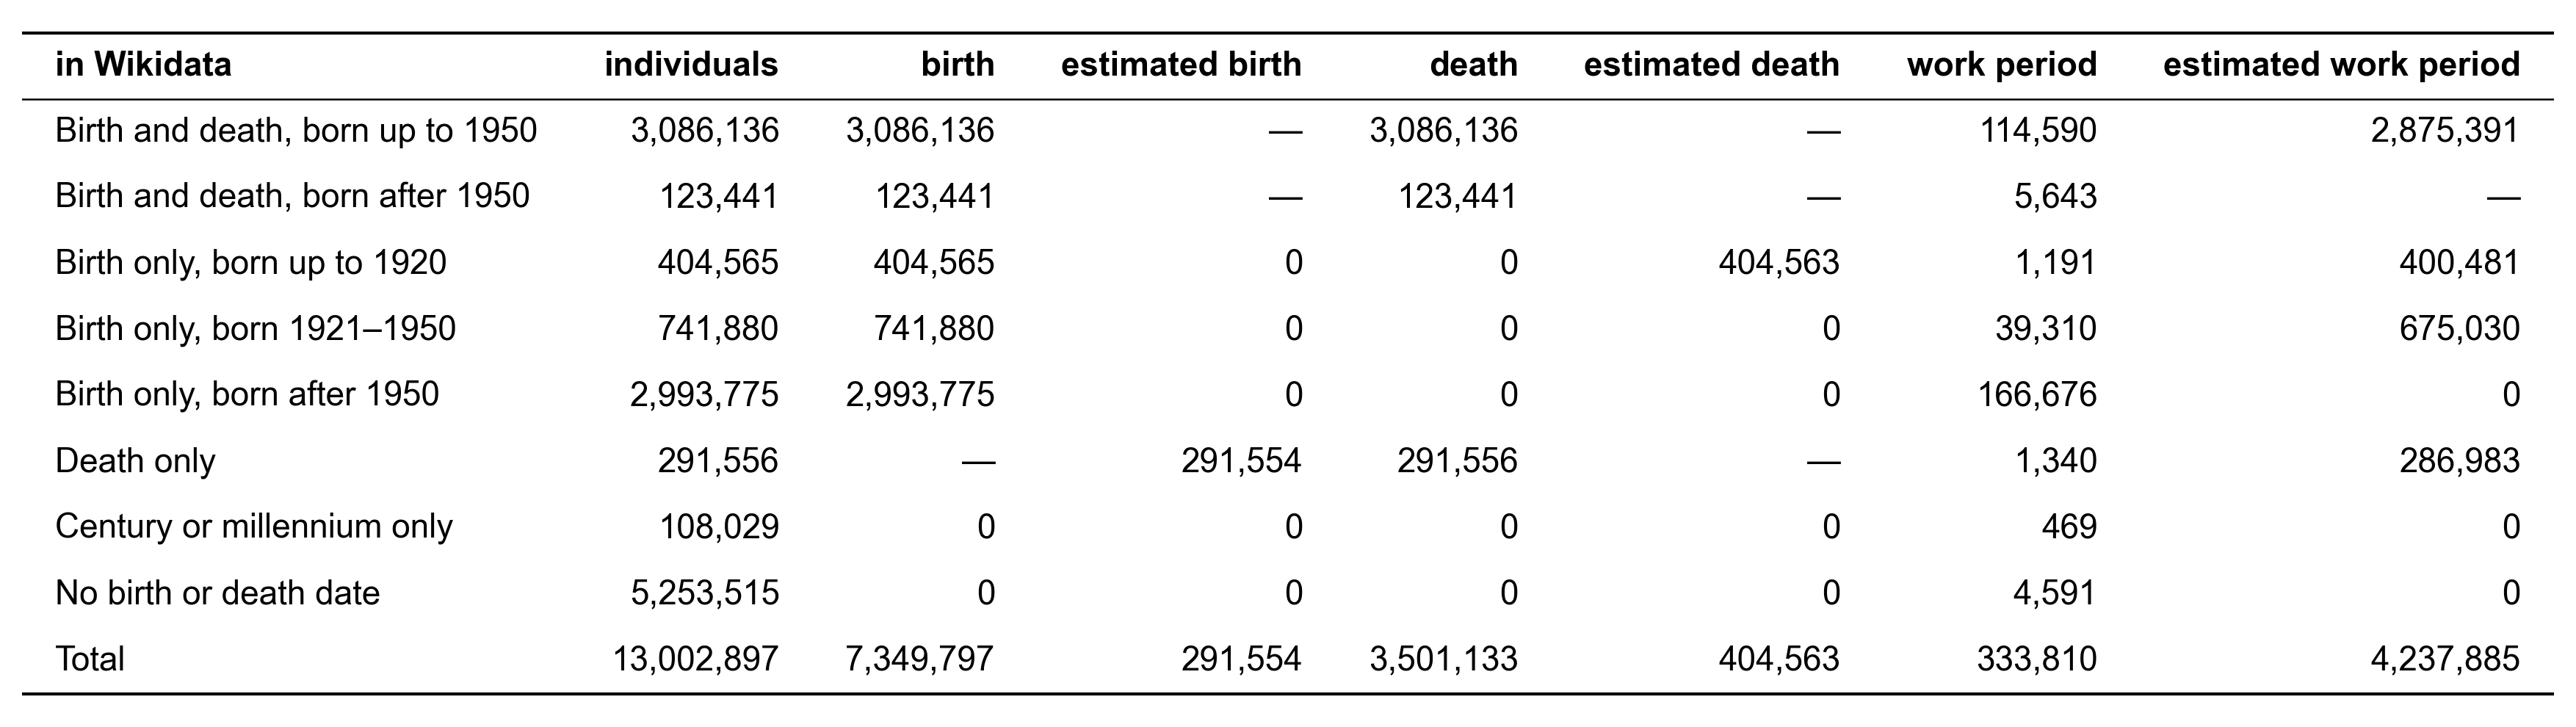

In [8]:
DASHED = ['Birth and death, born up to 1950', 'Birth and death, born after 1950', 'Death only']  # a dash instead of 0
dashed = pl.col('in Wikidata').is_in(DASHED)
show_table(by_group.with_columns(
    pl.when(dashed & (pl.col(column) == 0)).then(pl.lit('—')).otherwise(pl.col(column).map_elements(lambda v: f'{v:,}', return_dtype=pl.String)).alias(column)
    for column in by_group.columns[1:]
))

In [9]:
no_life_dates = dates.filter(pl.col('birth_year').is_null() & pl.col('death_year').is_null())
REMAINING = {
    'Dated works over several years (original work period)': counts['Original work period'],
    'Century or millennium only': pl.col('coarse'),
    'Floruit and dated works in a single year': pl.col('floruit') & single_year,
    'Dated works in a single year': single_year,
    'Floruit only': pl.col('floruit'),
    'No date': pl.lit(True),
}
remaining = (
    no_life_dates.with_columns(first_match(REMAINING).alias('dates'))
    .group_by('dates').agg(pl.len().alias('individuals'))
    .sort(pl.col('dates').replace_strict(list(REMAINING), list(range(len(REMAINING)))))
)
remaining = pl.concat([remaining, remaining.select(pl.lit('Total').alias('dates'), pl.col('individuals').sum())])
print(f'{no_life_dates.height:,} individuals with neither a birth nor a death year after the method')
remaining

5,361,544 individuals with neither a birth nor a death year after the method


dates,individuals
str,u32
"""Dated works over several years…",5060
"""Century or millennium only""",107560
"""Floruit and dated works in a s…",987
"""Dated works in a single year""",17229
"""Floruit only""",43799
"""No date""",5186909
"""Total""",5361544


### Table: individuals with neither a birth nor a death year after the method

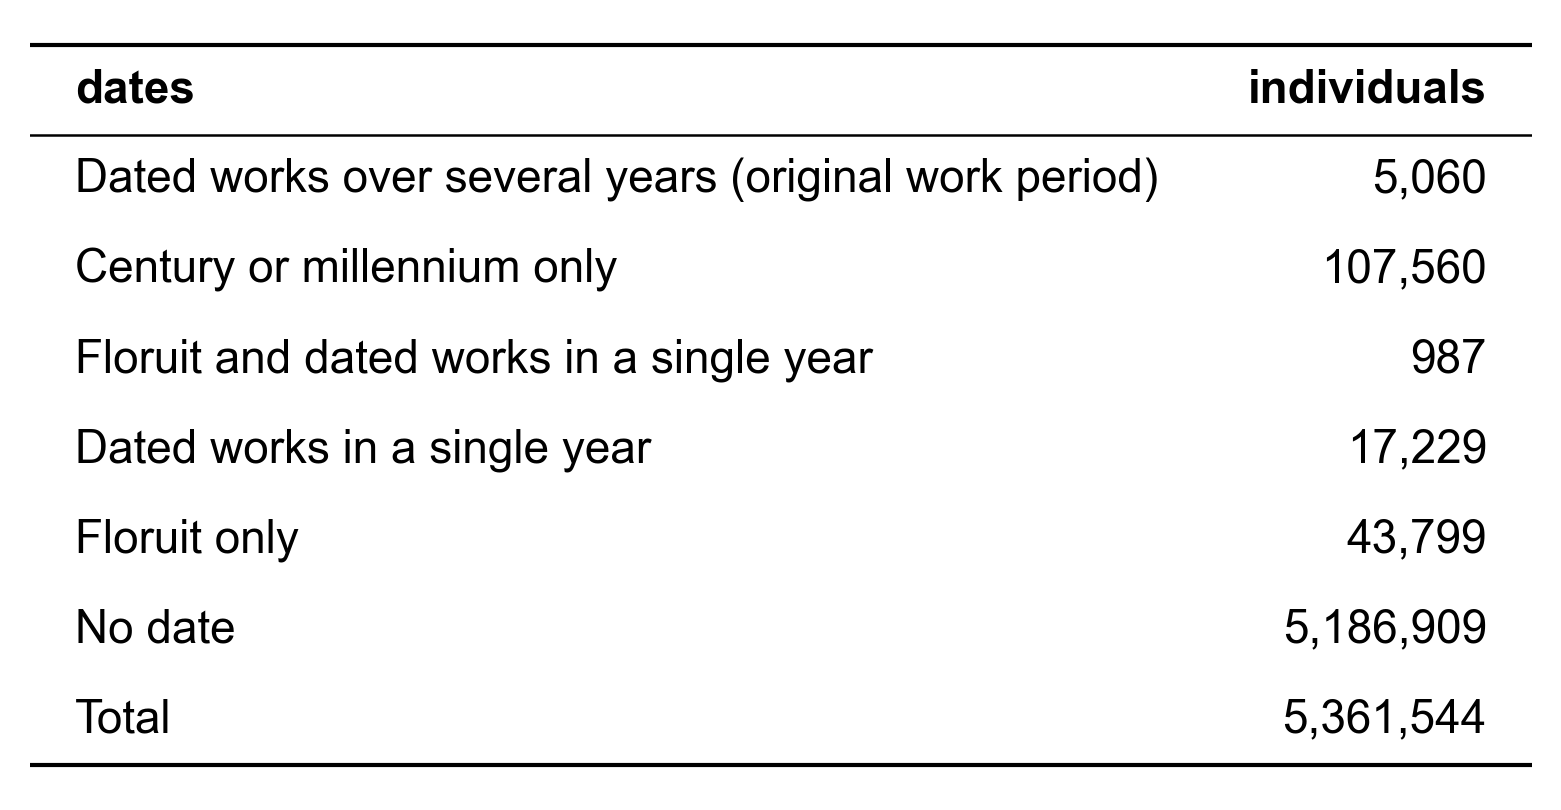

In [10]:
show_table(remaining)